**Eye-Tracking & Neurocognitive Intelligence | Vision-Based Gaze Estimation | Presented by: Reza Saadatyar (2026)**

**03 | Classical Gaze Estimation Baselines**

![Classical gaze-estimation workflow and recorded outer-LOPO results](../../images/03_classical_gaze_estimation_baselines.svg)

**Objective:** Compare a Training-derived mean-gaze reference with Histogram of Oriented Gradients (HOG) and regularised Ridge regression for unseen-person gaze estimation.

**Dataset:** 7,500 normalised left-eye images (36 × 60 pixels), paired 3D unit gaze directions and 15 participant-disjoint folds from [Notebook 02](02_eye_images_geometry_and_quality.ipynb).

**Main finding:** Participant-macro mean outer-Test error is **9.1601°** for mean direction and **7.5596°** for HOG + Ridge, a relative reduction of **17.47%**.

**Scope:** Internal LOPO on a study-defined MPIIGaze subset. The results are not an external validation or the official MPIIGaze benchmark.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess
repo_url="https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path=Path("/content")/repo_url.rsplit("/",1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git","clone","-q",repo_url,str(repo_path)],check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}

/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root=setup_colab("vision_based_gaze_estimation")

# ---------------------------- 2. Standard Library ----------------------------
import sys

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 4. Classical Modelling and Evaluation -------------------
from gaze_models import hog_descriptors, normalise_directions
from gaze_models import fit_ridge_and_predict
from gaze_geometry import angular_error_degrees
from mpiigaze_data import restore_indexed_eye_cache
from gaze_evaluation import load_image_cache, outer_fold_indices
from gaze_evaluation import validate_lopo_design, reconcile_outer_predictions

# ------------------- 5. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
# ----------------- 6. Shared and Project Research Utilities ------------------
from core.output_download import download_outputs_from_colab

# ----------------------- 7. Output Directory and Setup -----------------------
out_dir=root/"vision_based_gaze_estimation"/"output"
cache_path=root/"data"/"processed"/"mpiigaze"/"02_normalised_eye_cache.npz"
plot_style(font_family="DejaVu Sans", title_size=12.5,
 title_weight="normal",label_size=11.5,label_weight="normal",
 tick_size=11,legend_size=10,figure_dpi=100,figure_size=(9,4))
print("Output directory:",out_dir)
print("Image cache:",cache_path)
print("Python:",sys.version.split()[0])

Local changes kept; continuing with the current checkout. Conflicting Git update deferred.
Output directory: /content/Eye-Tracking-Neurocognitive-Intelligence/vision_based_gaze_estimation/output
Image cache: /content/Eye-Tracking-Neurocognitive-Intelligence/data/processed/mpiigaze/02_normalised_eye_cache.npz
Python: 3.13.16


**02. Reconcile Image and Gaze Inputs**

Use `02_sample_index.csv`, `02_fold_assignments.csv` and the corresponding local image cache. The cache reader matches ordered sample IDs and target directions; missing arrays can be recovered from the exact indexed MATLAB rows without resampling.

Each outer fold contains 6,000 Training images, 1,000 inner Validation images and 500 Test images from 12, two and one participants, respectively.

In [3]:
# ==================== 02. Reconcile Image and Gaze Inputs ====================

required=["02_sample_index.csv","02_fold_assignments.csv"]
missing=[x for x in required if not (out_dir/x).is_file()]
if missing:
    raise FileNotFoundError(f"Notebook 02 inputs missing: {missing}")
# Recover the exact Notebook 02 sample rows when the cache is absent.
if not cache_path.is_file():
    restore_indexed_eye_cache(
        root / "data" / "raw" / "mpiigaze",
        out_dir / "02_sample_index.csv", cache_path)
index,images,targets=load_image_cache(
 out_dir/"02_sample_index.csv",cache_path)
folds=pd.read_csv(out_dir/"02_fold_assignments.csv",
 dtype={"participant_id":str,"outer_test_person":str,"fold_id":str})
if folds.empty or folds.duplicated(["fold_id","participant_id"]).any():
    raise ValueError("Missing or repeated outer-fold participant assignments")
validate_lopo_design(index, folds)
print("Source-aligned images:",len(index))
print("Independent people:",index.participant_id.nunique())
print("Fixed outer folds:",folds.fold_id.nunique())

Source-aligned images: 7500
Independent people: 15
Fixed outer folds: 15


**03. Compute Classical Eye-Image Descriptors**

HOG describes local gradient orientations in each image. Six orientation bins, 6 × 6-pixel cells and one cell per block produce 360 features per crop (6 × 10 spatial cells × six bins). The descriptor matrix has shape `(7500, 360)`.

HOG uses image pixels only. Feature standardisation is fitted separately on each fold's Training images.

In [4]:
# ================ 03. Compute Classical Eye-Image Descriptors ================

features=hog_descriptors(images)
if len(features)!=len(index) or not np.isfinite(features).all():
    raise ValueError("HOG arrays do not match input sample identity")
print("HOG feature matrix:",features.shape)
print("No target or participant ID enters the image descriptor")

HOG feature matrix: (7500, 360)
No target or participant ID enters the image descriptor


**04. Fit and Select Models Within Each Outer Fold**

The mean-direction reference normalises the average Training gaze vector. HOG + Ridge fits three gaze components from standardised descriptors and normalises the predicted directions. Angular error is the inverse cosine of the clipped dot product between unit vectors, converted to degrees.

Ridge compares alpha values 1, 10 and 100 using inner Validation. Alpha 100 gives the lowest Validation error in all 15 folds; it is the best setting among those tested, not a global optimum. Both procedures use Training data for fitting and the held-out participant only for outer-Test scoring.

In [5]:
# ============= 04. Fit and Select Models Within Each Outer Fold ==============

# ---------------------------- 1. Candidate Design ----------------------------
SEED = 17
RIDGE_ALPHAS = (1., 10., 100.)
RUN_OUTER_TEST = True  # Full participant-disjoint outer LOPO.
if not RUN_OUTER_TEST:
    previously_scored = [
        name for name in ("03_baseline_outer_predictions.csv",
                          "03_baseline_fold_metrics.csv")
        if (out_dir / name).is_file()]
    if previously_scored:
        raise RuntimeError(
            "Saved outer-Test files exist in this checkout. Preserve those "
            "results and use a clean development checkout: "
            + str(previously_scored))
outer_rows, inner_rows = [], []

# ---------------------- 2. Train and Select Within Fold ----------------------
for fold_id in sorted(folds.fold_id.unique()):
    role = outer_fold_indices(index, folds, fold_id)
    i_train, i_val, i_test = (role[k] for k in
                              ("train", "validation", "test"))
    train_mean = normalise_directions(
        targets[i_train].mean(axis=0)[None])[0]
    prior_val = np.tile(train_mean, (len(i_val), 1))
    prior_error = float(angular_error_degrees(
        targets[i_val], prior_val).mean())
    inner_rows.append({
        "fold_id": fold_id, "model": "mean_direction",
        "alpha": np.nan, "selected": True,
        "inner_val_mean_angular_error_deg": prior_error,
        "n_inner_people": index.iloc[i_val].participant_id.nunique()})
    best_alpha, best_error = None, float("inf")
    for alpha in RIDGE_ALPHAS:
        candidate, pred_val = fit_ridge_and_predict(
            features[i_train], targets[i_train], features[i_val], alpha)
        error = float(angular_error_degrees(
            targets[i_val], pred_val).mean())
        inner_rows.append({
            "fold_id": fold_id, "model": "hog_ridge", "alpha": alpha,
            "selected": False, "inner_val_mean_angular_error_deg": error,
            "n_inner_people": index.iloc[i_val].participant_id.nunique()})
        if error < best_error:
            best_alpha, best_error = alpha, error
    inner_rows[-len(RIDGE_ALPHAS) + RIDGE_ALPHAS.index(best_alpha)][
        "selected"] = True

    if RUN_OUTER_TEST:
        selected, pred_ridge = fit_ridge_and_predict(
            features[i_train], targets[i_train],
            features[i_test], best_alpha)
        prior_test = np.tile(train_mean, (len(i_test), 1))
        for name, prediction in (("mean_direction", prior_test),
                                 ("hog_ridge", pred_ridge)):
            rows = index.iloc[i_test][["sample_id", "participant_id"]].copy()
            rows["fold_id"] = fold_id
            rows["model"] = name
            rows[["target_x", "target_y", "target_z"]] = targets[i_test]
            rows[["pred_x", "pred_y", "pred_z"]] = prediction
            rows["selected_inner_alpha"] = (
                best_alpha if name == "hog_ridge" else np.nan)
            outer_rows.append(rows)
    print(fold_id, "inner Validation Ridge alpha:", best_alpha)

inner_validation = pd.DataFrame(inner_rows)
print("Outer Test scoring enabled:", RUN_OUTER_TEST)
print("Inner candidate/fold rows:", len(inner_validation))

outer_01 inner Validation Ridge alpha: 100.0
outer_02 inner Validation Ridge alpha: 100.0
outer_03 inner Validation Ridge alpha: 100.0
outer_04 inner Validation Ridge alpha: 100.0
outer_05 inner Validation Ridge alpha: 100.0
outer_06 inner Validation Ridge alpha: 100.0
outer_07 inner Validation Ridge alpha: 100.0
outer_08 inner Validation Ridge alpha: 100.0
outer_09 inner Validation Ridge alpha: 100.0
outer_10 inner Validation Ridge alpha: 100.0
outer_11 inner Validation Ridge alpha: 100.0
outer_12 inner Validation Ridge alpha: 100.0
outer_13 inner Validation Ridge alpha: 100.0
outer_14 inner Validation Ridge alpha: 100.0
outer_15 inner Validation Ridge alpha: 100.0
Outer Test scoring enabled: True
Inner candidate/fold rows: 60


**05. Compare Inner Validation and Held-Out Predictions**

| Model | Mean inner-Validation error (°) | Participant-macro outer-Test error (°) |
|---|---:|---:|
| Mean direction | 9.0481 | 9.1601 |
| HOG + Ridge | 7.6961 | 7.5596 |

HOG + Ridge has lower inner-Validation error in 14 of 15 configurations; outer_03 is the exception. Validation groups overlap across folds. The outer-Test results cover 7,500 images per model, with 500 images per held-out person, so the participant-macro and pooled means coincide.

In [6]:
# =========== 05. Compare Inner Validation and Held-Out Predictions ===========

selected = inner_validation.loc[inner_validation.selected]
summary = (selected.groupby("model")
           .inner_val_mean_angular_error_deg
           .agg(n_folds="count", mean="mean", median="median", maximum="max")
           .reset_index())
display(summary)
print("Development summary: inner Validation only.")
if RUN_OUTER_TEST:
    outer_predictions = pd.concat(outer_rows, ignore_index=True)
    recorded, per_person = reconcile_outer_predictions(
        outer_predictions, index, folds, ("mean_direction", "hog_ridge"))
    outer_predictions = recorded
    print("Complete outer predictions:", len(outer_predictions))

,model,n_folds,mean,median,maximum
0,hog_ridge,15,7.696147,7.755132,8.764615
1,mean_direction,15,9.048065,9.100361,9.905420


Development summary: inner Validation only.
Complete outer predictions: 15000


**06. Save Classical Modelling Evidence**

The five outputs contain inner-Validation candidate results, selected configurations, a Validation comparison plot, 15,000 held-out predictions and 30 participant/model metric rows. Each prediction retains its sample, participant, fold, target and estimated 3D direction. The plot in this section shows inner Validation; the introductory SVG shows outer-Test participant errors.

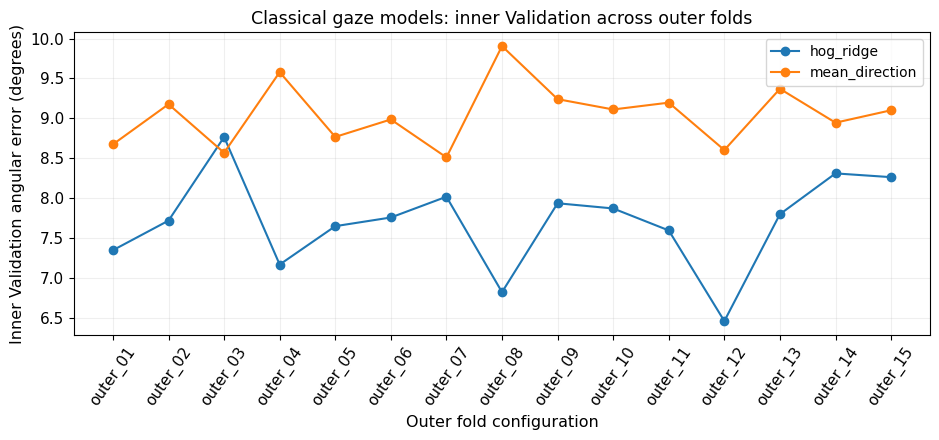

In [7]:
# =================== 06. Save Classical Modelling Evidence ===================

inner_validation.to_csv(
    out_dir / "03_inner_validation_metrics.csv", index=False)
configuration = selected[["fold_id", "model", "alpha"]].copy()
configuration = configuration.rename(columns={"alpha": "selected_alpha"})
configuration["run_mode"] = ("full_outer_lopo" if RUN_OUTER_TEST
                             else "development_inner_validation")
configuration["outer_fold_count"] = folds.fold_id.nunique()
configuration["test_used_for_selection"] = False
configuration.to_csv(out_dir / "03_run_configuration.csv", index=False)
fig, ax = plt.subplots(figsize=(9.5, 4.5))
for name, piece in selected.groupby("model"):
    ax.plot(piece.fold_id, piece.inner_val_mean_angular_error_deg,
            marker="o", label=name)
ax.set(title="Classical gaze models: inner Validation across outer folds",
       xlabel="Outer fold configuration",
       ylabel="Inner Validation angular error (degrees)")
ax.tick_params(axis="x", rotation=55)
ax.legend()
ax.grid(alpha=.2)
fig.tight_layout()
save_figure(fig, out_dir / "03_baseline_comparison.png")
plt.show()
if RUN_OUTER_TEST:
    outer_predictions.to_csv(
        out_dir / "03_baseline_outer_predictions.csv", index=False)
    per_person.to_csv(out_dir / "03_baseline_fold_metrics.csv", index=False)

**07. Interpretation and Output Download**

HOG + Ridge reduces mean held-out error by 1.6005° (17.47%) and has lower error for 14 of 15 participants. For p09, the mean-direction reference gives 8.6698° versus 9.6914° for HOG + Ridge. Image-based descriptors therefore do not improve every participant's result.

[Notebook 04](04_cnn_and_transfer_learning.ipynb) evaluates two neural models using the same indexed images and participant roles. [Notebook 05](05_cross_person_evaluation_and_robustness.ipynb) compares all four procedures and their paired uncertainty.

In [8]:
# ================== 07. Interpretation and Output Download ===================

needed = ["03_inner_validation_metrics.csv",
          "03_run_configuration.csv", "03_baseline_comparison.png"]
if RUN_OUTER_TEST:
    needed += ["03_baseline_outer_predictions.csv",
               "03_baseline_fold_metrics.csv"]
missing = [x for x in needed if not (out_dir / x).is_file()]
if missing:
    raise FileNotFoundError(f"Stage-03 outputs missing: {missing}")
print("Inner Validation candidate/fold rows:", len(inner_validation))
print("Outer Test scored:", RUN_OUTER_TEST)
print("Next: complete Notebook 04, then compare all four models in Notebook 05")
(out_dir / "03_run_configuration.json").unlink(missing_ok=True)
download_outputs_from_colab("vision_based_gaze_estimation/output", "03")

Inner Validation candidate/fold rows: 60
Outer Test scored: True
Next: complete Notebook 04, then compare all four models in Notebook 05
------------------------------------------------------------------------
Notebook 03
Files packaged: 5
  + 03_baseline_comparison.png
  + 03_baseline_fold_metrics.csv
  + 03_baseline_outer_predictions.csv
  + 03_inner_validation_metrics.csv
  + 03_run_configuration.csv
Download ZIP from Colab Contents: /content/vision_based_gaze_estimation_Notebook_03_Outputs.zip
